In [1]:
### follow the file to analyze generic cubic and linear band spectrum 

In [57]:
import time
import sys
import os

# Add the parent directory to sys.path
notebook_path = os.getcwd()  # Get the current working directory where the notebook is located
parent_directory = os.path.dirname(notebook_path)  # Move to the parent directory
sys.path.append(parent_directory)

# Now you can import config
from config import *
#from Minimal_Model_2D import *
#import Minimal_Model_2D as mm2d
import time

np.set_printoptions(threshold=sys.maxsize)
#from Minimal_Model_1D import *

#import Minimal_Model_1D as M

from Minimal_Model_1D import *


In [108]:
class modified_spin_orbit(oneD_Minimal_Model):

    def spin_orbit(self, i, j, s, so='cu', kx=0):

        """
        returns  <i,s|H_SO|j,sp>
        
        Args:
            i, j (int): refers to i and j th y subband sho wavefunction 
            s, sp (int){0 or 1}: refers to spin index up and down resp. for spin orbit, sp is opposite of s for spin orbit to be non zero
            so : spin orbit coupling, 'cu' if cubic rashba, 'li' if linear rashba
        
        """

        if so == 'cu':
            #print('cu')
            # cubic SOC #

            #k_minus_cube = self.onedOP.KxCu(kx)*self.Ky_iden_pr(i,j) - 1j*3*self.onedOP.KxSq(kx)*self.Ky_pr(i,j) - 3*self.onedOP.Kx(kx)*self.Kysq_pr(i,j) + 1j*self.Kycube_pr(i,j)*self.onedOP.iden()
            #k_plus_cube =  self.onedOP.KxCu(kx)*self.Ky_iden_pr(i,j) + 1j*3*self.onedOP.KxSq(kx)*self.Ky_pr(i,j) - 3*self.onedOP.Kx(kx)*self.Kysq_pr(i,j) - 1j*self.Kycube_pr(i,j)*self.onedOP.iden() 

            ### simplified cubic ###
            k_minus_cube = self.onedOP.KxCu(kx)*self.Ky_iden_pr(i,j) - 1j*3*self.onedOP.KxSq(kx)*self.Ky_pr(i,j) - 3*self.onedOP.Kx(kx)*self.Kysq_pr(i,j) + 1j*self.Kycube_pr(i,j)*self.onedOP.iden()
            k_plus_cube =  self.onedOP.KxCu(kx)*self.Ky_iden_pr(i,j) + 1j*3*self.onedOP.KxSq(kx)*self.Ky_pr(i,j) - 3*self.onedOP.Kx(kx)*self.Kysq_pr(i,j) - 1j*self.Kycube_pr(i,j)*self.onedOP.iden() 


            ### Note in later definitions, soc coupling is evoked only when s!=s' ###
            ### Hence not coding that statement here ###  

            if s==0:
                
                return -1j*self.alphat*k_minus_cube
            
            else:

                return 1j*self.alphat*k_plus_cube

        elif so == 'li':
            #print('li')
            # Linear SOC #

            if i==j:

                ### Note in later definitions, soc coupling is evoked only when s!=s' ###
                ### Hence not coding that statement here ###
                if s ==0 : 

                    return 1j*self.alphat*(self.onedOP.Kx(kx))
                
                else:

                    return -1j*self.alphat*(self.onedOP.Kx(kx))
                
            else :

                return self.alphat*(self.Ky_pr(i,j))*self.onedOP.iden()      
        
        else:

            return self.onedOP.zer()

In [112]:
N = 6
NSM = 2
NSC = 2
MY = 2
AX = 1
OMEGA = 5 #IN MEv
ALPHAT = 1000


#M_per = oneD_Minimal_Model(N, NSM, NSC, MY, AX, OMEGA, ALPHAT, px=True)
M_per = modified_spin_orbit(N, NSM, NSC, MY, AX, OMEGA, ALPHAT, px=True)

KX = np.linspace(-math.pi/6, math.pi/6, 151)

KNUM = 3

Ep = np.empty((KX.shape[0],KNUM))

for i in range(KX.shape[0]):

    H = M_per.HN(kx=KX[i])

    E = eigsh(H, k=KNUM, return_eigenvectors=False, which='SA')

    #Es = np.sort(E)

    Ep[i, :] = E

    if i%5 == 0:

        print(i)


    

0
5
10
15
20
25
30
35
40
45
50
55
60
65
70
75
80
85
90
95
100
105
110
115
120
125
130
135
140
145
150


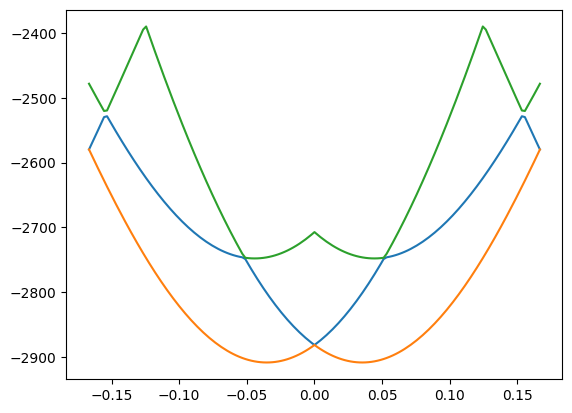

In [113]:
plt.plot(KX/np.pi, Ep[:,1])
plt.plot(KX/np.pi, Ep[:,2])
plt.plot(KX/np.pi, Ep[:,0])
#plt.ylim(ymax=-10500, ymin = -10620)
#plt.xlim(xmin= -0.05, xmax=0.05)

(-2925.0, -2750.0)

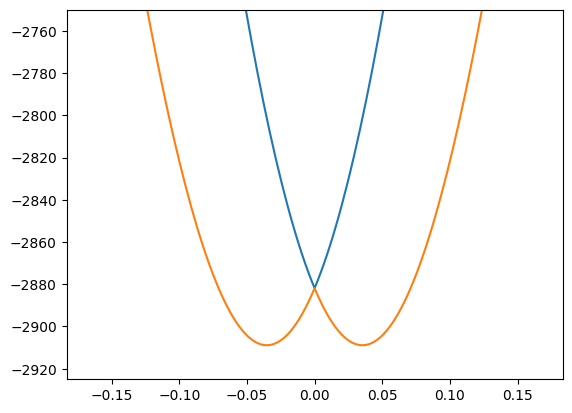

In [116]:
plt.plot(KX/np.pi, Ep[:,1])
plt.plot(KX/np.pi, Ep[:,2])
#plt.plot(KX/np.pi, Ep[:,0])
plt.ylim(ymax=-2750, ymin = -2925)
#plt.xlim(xmin= -0.07, xmax=0.07)

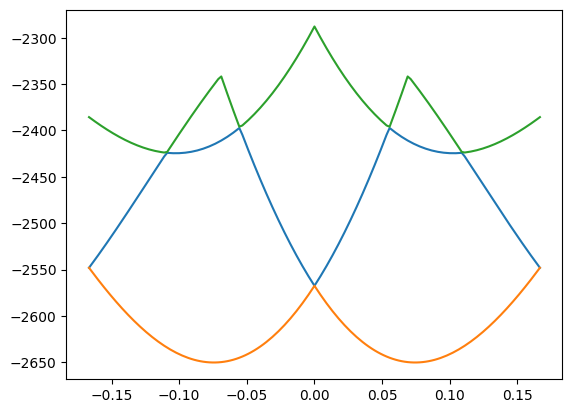

In [92]:
plt.plot(KX/np.pi, Ep[:,1])
plt.plot(KX/np.pi, Ep[:,2])
plt.plot(KX/np.pi, Ep[:,0])
#plt.ylim(ymax=-10500, ymin = -10620)
#plt.xlim(xmin= -0.05, xmax=0.05)

(-2100.0, -2000.0)

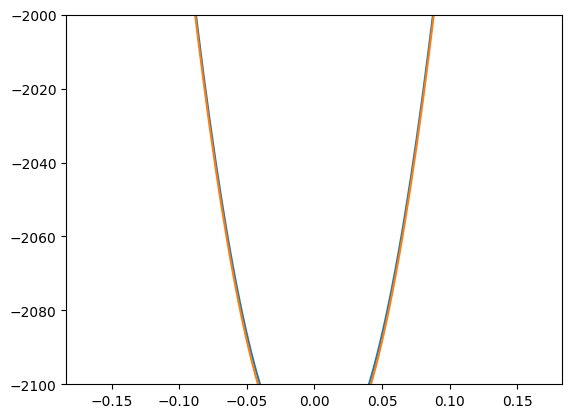

In [83]:
plt.plot(KX/np.pi, Ep[:,1:])
plt.ylim(ymin=-2100, ymax = -2000)
#plt.xlim(xmin= -0.05, xmax=0.05)

In [74]:
N = 6
NSM = 2
NSC = 2
MY = 2
AX = 1
OMEGA = 2 #IN MEv
ALPHAT = 1000


M_per = oneD_Minimal_Model(N, NSM, NSC, MY, AX, OMEGA, ALPHAT, px=True)

KX = np.linspace(-math.pi/6, math.pi/6, 151)

KNUM = 3

Ep = np.empty((KX.shape[0],KNUM))

for i in range(KX.shape[0]):

    H = M_per.HN(kx=KX[i])

    E = eigsh(H, k=KNUM, return_eigenvectors=False, which='SA')

    #Es = np.sort(E)

    Ep[i, :] = E

    if i%5 == 0:

        print(i)

0
5
10
15
20
25
30
35
40
45
50
55
60
65
70
75
80
85
90
95
100
105
110
115
120
125
130
135
140
145
150


(-0.07, 0.07)

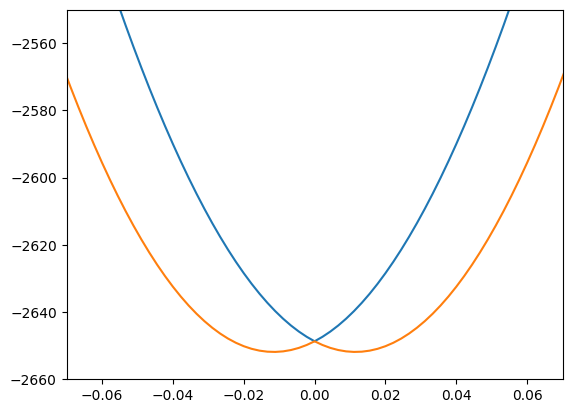

In [78]:
plt.plot(KX/np.pi, Ep[:,1:])
plt.ylim(ymin=-2660, ymax = -2550)
plt.xlim(xmin= -0.07, xmax=0.07)

In [9]:
N = 6
NSM = 2
NSC = 2
MY = 2
AX = 1
OMEGA = 2 #IN MEv
ALPHAT = 20


M_per = M.oneD_Minimal_Model(N, NSM, NSC, MY, AX, OMEGA, ALPHAT, px=True)

KX = np.linspace(-math.pi/6, math.pi/6, 101)

KNUM = 3

Ep = np.empty((KX.shape[0],KNUM))

for i in range(KX.shape[0]):

    H = M_per.HN(so='li', kx=KX[i])

    E = eigsh(H, k=KNUM, return_eigenvectors=False, which='SA')

    #Es = np.sort(E)

    Ep[i, :] = E

    if i%5 == 0:

        print(i)

0
5
10
15
20
25
30
35
40
45
50
55
60
65
70
75
80
85
90
95
100


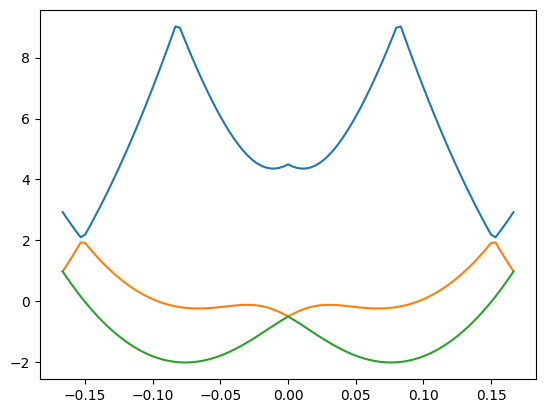

In [10]:
plt.plot(KX/np.pi, Ep)
#plt.ylim(ymin=-10460, ymax = -10350)
#plt.xlim(xmin= -0.05, xmax=0.05)

(-3.0, 0.0)

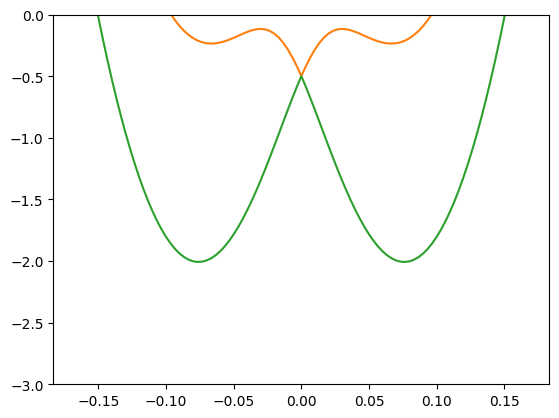

In [11]:
plt.plot(KX/np.pi, Ep)
plt.ylim(ymin=-3, ymax = 0)
#plt.xlim(xmin= -0.05, xmax=0.05)

In [18]:
N = 6
NSM = 2
NSC = 2
MY = 1
AX = 1
OMEGA = 2 #IN MEv
ALPHAT = 20


M_per = M.oneD_Minimal_Model(N, NSM, NSC, MY, AX, OMEGA, ALPHAT, px=True)

KX = np.linspace(-math.pi/6, math.pi/6, 101)

KNUM = 3

Ep = np.empty((KX.shape[0],KNUM))

for i in range(KX.shape[0]):

    H = M_per.HN(so='li', kx=KX[i])

    E = eigsh(H, k=KNUM, return_eigenvectors=False, which='SA')

    #Es = np.sort(E)

    Ep[i, :] = E

    if i%5 == 0:

        print(i)

0
5
10
15
20
25
30
35
40
45
50
55
60
65
70
75
80
85
90
95
100


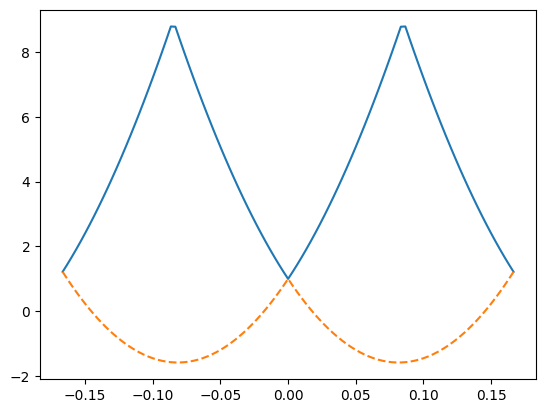

In [19]:
#plt.plot(KX/np.pi, Ep[:,0])
plt.plot(KX/np.pi, Ep[:,1], linestyle='solid')
plt.plot(KX/np.pi, Ep[:,2], linestyle='dashed')
#plt.ylim(ymin=-10460, ymax = -10350)
#plt.xlim(xmin= -0.05, xmax=0.05)

0
5
10
15
20
25
30
35
40
45
50
55
60
65
70
75
80
85
90
95
100


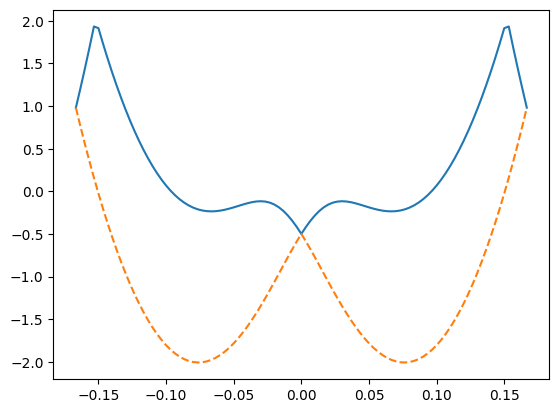

In [20]:
N = 6
NSM = 2
NSC = 2
MY = 2
AX = 1
OMEGA = 2 #IN MEv
ALPHAT = 20


M_per = M.oneD_Minimal_Model(N, NSM, NSC, MY, AX, OMEGA, ALPHAT, px=True)

KX = np.linspace(-math.pi/6, math.pi/6, 101)

KNUM = 3

Ep = np.empty((KX.shape[0],KNUM))

for i in range(KX.shape[0]):

    H = M_per.HN(so='li', kx=KX[i])

    E = eigsh(H, k=KNUM, return_eigenvectors=False, which='SA')

    #Es = np.sort(E)

    Ep[i, :] = E

    if i%5 == 0:

        print(i)

#plt.plot(KX/np.pi, Ep[:,0])
plt.plot(KX/np.pi, Ep[:,1], linestyle='solid')
plt.plot(KX/np.pi, Ep[:,2], linestyle='dashed')
#plt.ylim(ymin=-10460, ymax = -10350)
#plt.xlim(xmin= -0.05, xmax=0.05)

0
5
10
15
20
25
30
35
40
45
50
55
60
65
70
75
80
85
90
95
100


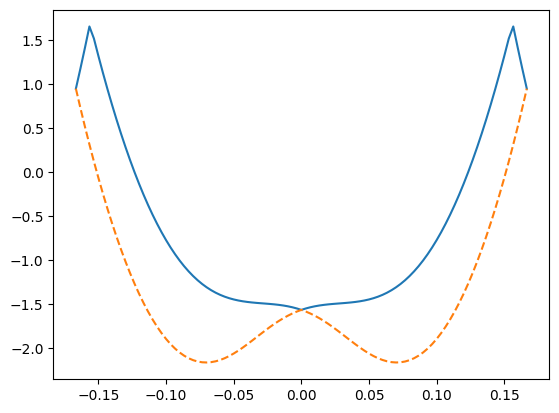

In [21]:
N = 6
NSM = 2
NSC = 2
MY = 5
AX = 1
OMEGA = 2 #IN MEv
ALPHAT = 20


M_per = M.oneD_Minimal_Model(N, NSM, NSC, MY, AX, OMEGA, ALPHAT, px=True)

KX = np.linspace(-math.pi/6, math.pi/6, 101)

KNUM = 3

Ep = np.empty((KX.shape[0],KNUM))

for i in range(KX.shape[0]):

    H = M_per.HN(so='li', kx=KX[i])

    E = eigsh(H, k=KNUM, return_eigenvectors=False, which='SA')

    #Es = np.sort(E)

    Ep[i, :] = E

    if i%5 == 0:

        print(i)

#plt.plot(KX/np.pi, Ep[:,0])
plt.plot(KX/np.pi, Ep[:,1], linestyle='solid')
plt.plot(KX/np.pi, Ep[:,2], linestyle='dashed')
#plt.ylim(ymin=-10460, ymax = -10350)
#plt.xlim(xmin= -0.05, xmax=0.05)